# Integration backwards of the orbit of the stars we got from the Ibata et al. (2024) data 

In this file, we take the already cleaned data from the Ibata et al. (2024) and integrate backwards the positions of the stars to help generate initial conditions resembling reality.

In [1]:
import pandas as pd
import numpy as np
import astropy.units as u
from galpy.orbit import Orbit
from galpy.potential import MWPotential2014

We use data that has already been cleand previously, i.e. stars that have all the observables in the 6d space available.

In [2]:
df_target = pd.read_csv('stars_6D_Ibata2024.csv')
print(f"Data Loaded : {len(df_target)} stars.")
print(df_target.columns)

Data Loaded : 1703 stars.
Index(['RA', 'Dec', 'Distance_kpc', 'pmRA', 'pmDec', 'Vlos', 'Stream_ID'], dtype='object')


A first guess would be to integrate all the positions backwards in time 

In [7]:
o = Orbit(vxvv=np.column_stack([
    df_target['RA'].values,
    df_target['Dec'].values,
    df_target['Distance_kpc'].values,
    df_target['pmRA'].values,
    df_target['pmDec'].values,
    df_target['Vlos'].values
]), radec=True)

# integration time  
ts = np.linspace(0, -2, 1000) * u.Gyr

# MWPotential2014 (Bovy 2015)
print(f"integration for {len(df_target)} backwards for 2 Gyr...")
o.integrate(ts, MWPotential2014)

# Galactocentric data at t = -2 Gyr
# .x, .y, .z [kpc]
# .vx, .vy, .vz  [km/s]

x_past = o.x(ts[-1])
y_past = o.y(ts[-1])
z_past = o.z(ts[-1])
vx_past = o.vx(ts[-1])
vy_past = o.vy(ts[-1])
vz_past = o.vz(ts[-1])

# New DataFrame for ICs
df_initial_conditions = pd.DataFrame({
    'x_kpc': x_past,
    'y_kpc': y_past,
    'z_kpc': z_past,
    'vx_kms': vx_past,
    'vy_kms': vy_past,
    'vz_kms': vz_past,
    'Stream_ID': df_target['Stream_ID'].values
})

# mask for particles at a reasonable distnace 
mask = np.sqrt(df_initial_conditions['x_kpc']**2 + df_initial_conditions['y_kpc']**2 + df_initial_conditions['z_kpc']**2) < 50
df_initial_maked = df_initial_conditions[mask].reset_index(drop=True)
o_masked = o[mask]
print("done...")
print(df_initial_conditions.head())

# # Save for AGAMA Later
# df_initial_conditions.to_csv("IC_for_.csv", index=False)

integration for 1703 backwards for 2 Gyr...


done...
        x_kpc        y_kpc        z_kpc      vx_kms       vy_kms       vz_kms  \
0  -19.213883    -5.655933    26.225036   10.065078  -114.918451   -28.523618   
1   33.760909    21.004959   -51.638584  -64.248641    46.121858   137.989396   
2  -31.524491 -1773.471784 -1647.207374   26.892578   904.904084   756.191692   
3 -373.678424 -3091.073222 -2696.098031  202.191321  1584.026779  1220.451870   
4   -8.927466    14.783529    12.778682 -112.285917   -61.120189   151.039621   

   Stream_ID  
0          1  
1          1  
2          1  
3          1  
4          1  


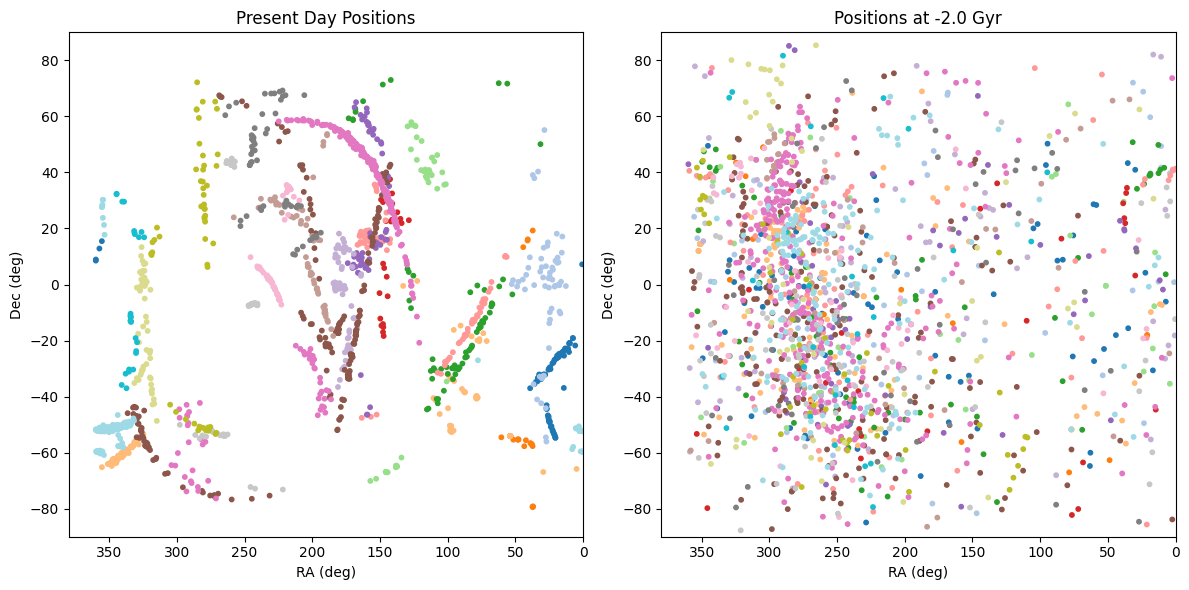

In [ ]:
# Plotting the past and present orbits
import matplotlib.pyplot as plt 
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(df_target['RA'], df_target['Dec'], s=10, c=df_target['Stream_ID'], cmap ='tab20')
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.xlim(0, 380)
plt.ylim(-90, 90)
plt.title('Present Day Positions')
plt.gca().invert_xaxis()

plt.subplot(1, 2, 2)
ra_past = o.ra(ts[-1])
dec_past = o.dec(ts[-1])

plt.scatter(ra_past, dec_past, s=10, c=df_target['Stream_ID'], cmap ='tab20')
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.xlim(0, 380)
plt.ylim(-90, 90)
plt.title(f'Positions at {ts[-1]}')
plt.gca().invert_xaxis()

plt.tight_layout()
plt.show()



✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


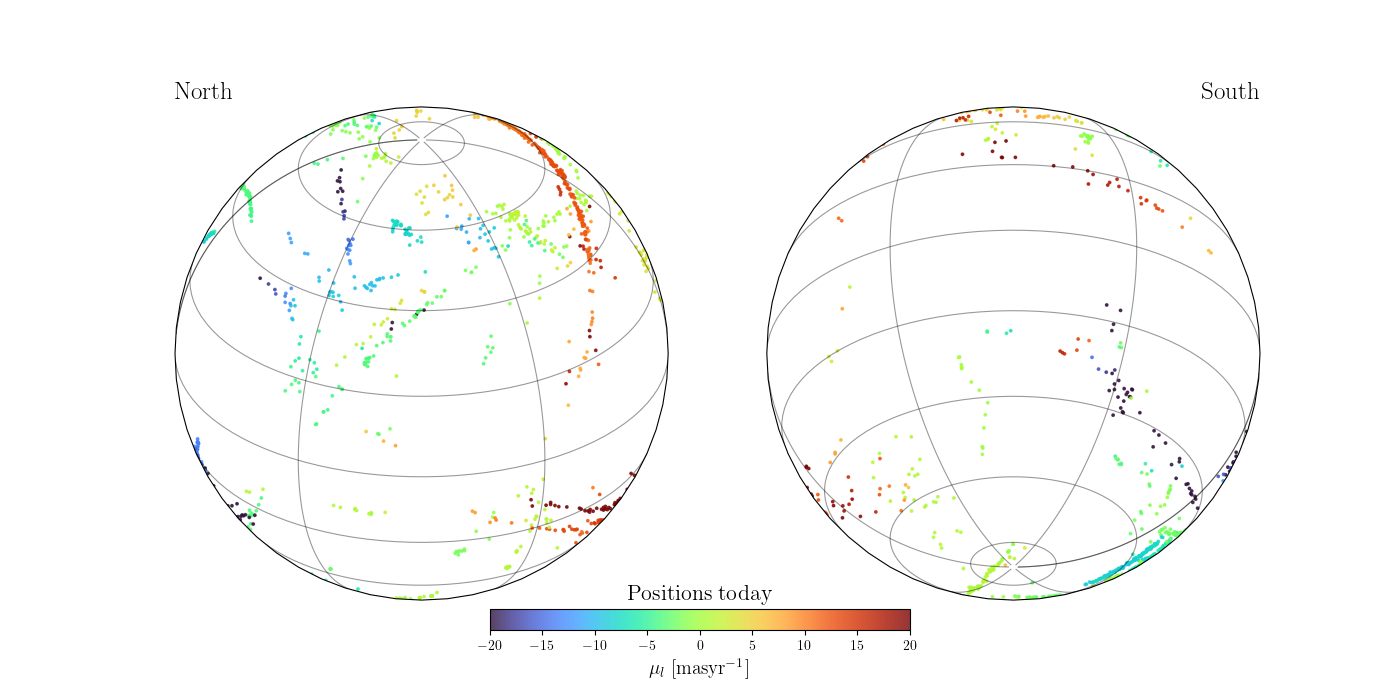

In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from adri_plotstyle import init_plot_style
init_plot_style(14)

l = -o.ll(0) + 180     
b = o.bb(0)      
pm_l = o.pmll(0) 

fig = plt.figure(figsize=(14, 7))

proj_north = ccrs.Orthographic(central_longitude=270.0, central_latitude=30.0)

ax1 = fig.add_subplot(121, projection=proj_north)
ax1.set_global() 

gl1 = ax1.gridlines(draw_labels=False, color='black', alpha=0.4, linestyle='-')

sc1 = ax1.scatter(l, b, c=pm_l, cmap='turbo', s=3, alpha=0.8, 
                  vmin=-20, vmax=20, transform=ccrs.Geodetic())

ax1.set_title("$\mathrm{North}$", loc='left', fontsize=18)

proj_south = ccrs.Orthographic(central_longitude=90.0, central_latitude=-30.0)

ax2 = fig.add_subplot(122, projection=proj_south)
ax2.set_global()

gl2 = ax2.gridlines(draw_labels=False, color='black', alpha=0.4, linestyle='-')

sc2 = ax2.scatter(l, b, c=pm_l, cmap='turbo', s=3, alpha=0.8, 
                  vmin=-20, vmax=20, transform=ccrs.Geodetic())

ax2.set_title("$\mathrm{South}$", loc='right', fontsize=18)

cbar_ax = fig.add_axes([0.35, 0.1, 0.3, 0.03]) 
cbar = fig.colorbar(sc1, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r'$\mu_l \mathrm{\ [mas\ yr^{-1}]}$', fontsize=14)
plt.title("$\mathrm{Positions\ today}$", fontsize=16)
plt.savefig("../plots/positions_today.png", dpi=600, bbox_inches='tight')
plt.show()

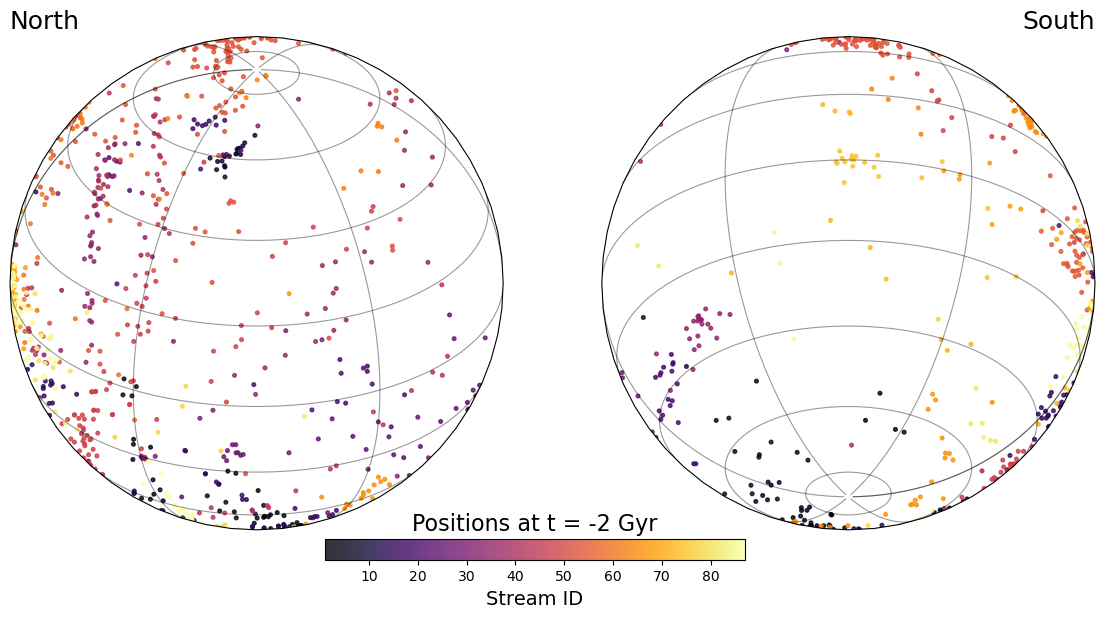

In [101]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

l = -o_masked.ll(-1) + 180     
b = o_masked.bb(-1)      
ids = df_initial_maked['Stream_ID']

fig = plt.figure(figsize=(14, 7))

proj_north = ccrs.Orthographic(central_longitude=270.0, central_latitude=30.0)

ax1 = fig.add_subplot(121, projection=proj_north)
ax1.set_global() 

gl1 = ax1.gridlines(draw_labels=False, color='black', alpha=0.4, linestyle='-')

sc1 = ax1.scatter(l, b, c=ids, cmap='inferno', s=7, alpha=0.8, 
                  transform=ccrs.Geodetic())

ax1.set_title("North", loc='left', fontsize=18)

proj_south = ccrs.Orthographic(central_longitude=90.0, central_latitude=-30.0)

ax2 = fig.add_subplot(122, projection=proj_south)
ax2.set_global()

gl2 = ax2.gridlines(draw_labels=False, color='black', alpha=0.4, linestyle='-')

sc2 = ax2.scatter(l, b, c=ids, cmap='inferno', s=7, alpha=0.8, 
                  transform=ccrs.Geodetic())

ax2.set_title("South", loc='right', fontsize=18)

cbar_ax = fig.add_axes([0.35, 0.1, 0.3, 0.03]) 
cbar = fig.colorbar(sc1, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Stream ID', fontsize=14)
plt.title("Positions at t = -2 Gyr", fontsize=16)
plt.show()
plt.show()

It appears difficult to define the center of a given cluster or stream because positions are relly scattered. That's why we attempt another method.

### Another try where we average the stars initially before computing any orbit bacwards

Here, we evaluate the median first and then integrate starting from that positon. Exactitude is not really necessary, but what we seek is to obtain some initial positions and velocities that are physically acurate an that we can use to boost the cluster later on.

In [10]:
df_present_centers = df_target.groupby('Stream_ID').median().reset_index()
print("Present day centers of the streams :")
print(df_present_centers)


Present day centers of the streams :
    Stream_ID          RA        Dec  Distance_kpc    pmRA   pmDec     Vlos
0           1  357.217906   8.925398     16.666667 -0.6070  1.4460 -115.220
1           2    5.850603 -21.754506     17.241379  1.5240  2.0060   47.270
2           3   11.184188 -24.075803     10.309278  4.1820 -5.2780  -30.720
3           4   22.270861 -27.957844     13.611111 -0.0845 -0.9690  -99.165
4           5   23.659403 -50.528719     11.627907  2.7240 -0.0860   52.240
..        ...         ...        ...           ...     ...     ...      ...
79         82  342.385421  30.910293     10.555250 -3.0305 -4.6725 -136.500
80         83  341.942761 -54.337714      8.480088  0.9770 -8.8470  -67.510
81         85  354.770158  27.748334     41.666667  1.2310 -2.8230 -193.500
82         86  344.339606 -51.101190      9.580125  6.8825 -4.9590  -18.855
83         87  356.677008 -59.565878     13.888889 -0.1600 -1.6560 -104.400

[84 rows x 7 columns]


In [21]:

seeds_list = []
ts = np.linspace(0, -2, 1000) * u.Gyr

print("computing the progenitors seeds ...")

l = []
b = []
pml = []
print("velocity of the progenitor of stream at t = -2 Gyr : ")
print(len(df_present_centers))
for index, row in df_present_centers.iterrows():
    sid = int(row['Stream_ID'])
    
    # creating the central orbit one single particle per stream
    o_center = Orbit(vxvv=[
        row['RA'], 
        row['Dec'], 
        row['Distance_kpc'], # Distance
        row['pmRA'], 
        row['pmDec'], 
        row['Vlos']
    ], radec=True)
    
    # bacwards integration for 2 Gyr
    o_center.integrate(ts, MWPotential2014)
    
    # On récupère le point final (-2 Gyr)
    x_prog = o_center.x(ts[-1])
    y_prog = o_center.y(ts[-1])
    z_prog = o_center.z(ts[-1])
    vx_prog = o_center.vx(ts[-1])
    vy_prog = o_center.vy(ts[-1])
    vz_prog = o_center.vz(ts[-1])

    r = np.sqrt(x_prog**2 + y_prog**2 + z_prog**2)
    if r<= 100:  # Only keep progenitors within 100 kpc
        l.append(o_center.ll(ts[-1]))
        b.append(o_center.bb(ts[-1]))
        pml.append(o_center.pmll(ts[-1]))
        seeds_list.append([int(sid), x_prog, y_prog, z_prog, vx_prog, vy_prog, vz_prog])
       # print(vx_prog, vy_prog, vz_prog, "norm = ",  np.sqrt(vx_prog**2 + vy_prog**2 + vz_prog**2), " km/s" )

        #writing the orbit in a file 
        with open(f"orbits/orbit_{sid}.txt", "w") as f:
            x = np.array(o_center.x(ts))
            y = np.array(o_center.y(ts))
            z = np.array(o_center.z(ts))
            vx = np.array(o_center.vx(ts))
            vy = np.array(o_center.vy(ts))
            vz = np.array(o_center.vz(ts))
            Data = np.column_stack((x, y, z, vx, vy, vz))
            np.savetxt(f, Data, header="x(kpc) y(kpc) z(kpc) vx(km/s) vy(km/s) vz(km/s)")
            del Data, x, y, z, vx, vy, vz  # free memory


# Sving the array
l = np.array(l)
b = np.array(b)
seeds_array = np.array(seeds_list)
np.save("SWIFT_seeds.npy", seeds_array)
print(seeds_array)

print("Seeds for SWIFThave been saved")
print(f"number of progenitors : {len(seeds_array)}")
print("\nStructure of the array : [Stream_ID, x, y, z, vx, vy, vz]")

computing the progenitors seeds ...
velocity of the progenitor of stream at t = -2 Gyr : 
84
[[ 1.00000000e+00  3.15688207e+01 -8.86093744e+00 -6.89725911e+01
   2.27937901e+01  7.34549551e+01 -8.54828469e+00]
 [ 3.00000000e+00  5.71244295e+00 -3.54157373e+00  8.65416167e+00
   6.37123004e+00 -1.42806681e+02  5.92568672e+01]
 [ 4.00000000e+00  1.42353828e+01  3.09088343e+00 -1.96720263e+01
  -1.01673981e+02  1.02858534e+02  6.15404370e+01]
 [ 5.00000000e+00  9.45294189e+00  1.58930038e+00 -3.55126835e+00
  -1.46954196e+01  1.27646442e+02 -1.77826319e+02]
 [ 6.00000000e+00 -1.06368905e+01 -2.01072103e+01  6.86340849e+00
   9.44744582e+00 -1.59256564e+02 -1.15729735e+02]
 [ 8.00000000e+00  9.70900311e+00  1.06541885e+00  1.04244304e+01
   1.48393980e+02  1.43337353e+02 -4.32995498e+00]
 [ 9.00000000e+00 -3.00596630e+00 -7.81056787e+00 -3.76433289e+00
   1.80648584e+02 -3.21742252e+01  1.33567561e+02]
 [ 1.10000000e+01  1.93950994e+01 -1.89604004e+01  3.49683861e+01
  -3.97412504e+01  1.2

We are eventually left with 75 different pos/vel, this means that we can generate 75 different ICs that we will simulate with SWIFT

✅ Matplotlib LaTeX style initialisé (Police: helvet, Taille: 12)


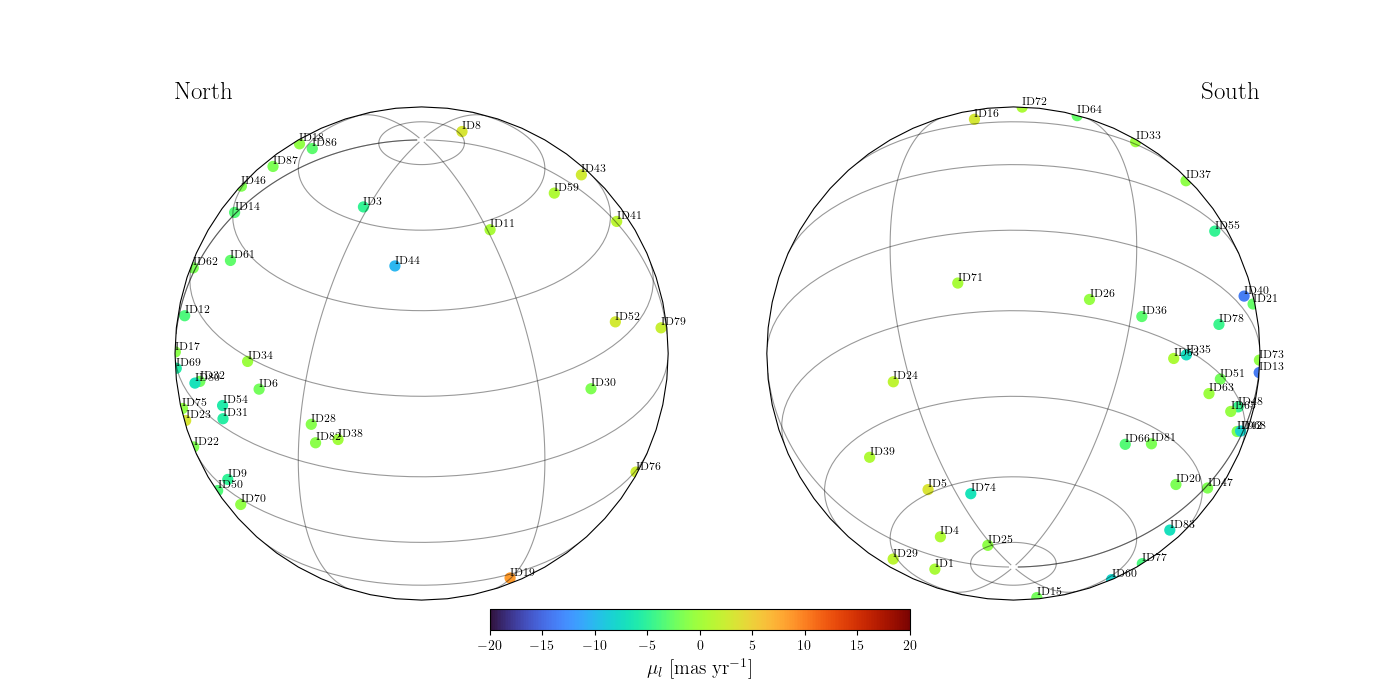

In [32]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from adri_plotstyle import init_plot_style
init_plot_style(14)

ts = np.linspace(0, -2, 1000) * u.Gyr

l = -l + 180           
ids = seeds_array[:, 0]


fig = plt.figure(figsize=(14, 7))

proj_north = ccrs.Orthographic(central_longitude=270.0, central_latitude=30.0)

ax1 = fig.add_subplot(121, projection=proj_north)
ax1.set_global() 

gl1 = ax1.gridlines(draw_labels=False, color='black', alpha=0.4, linestyle='-')

sc1 = ax1.scatter(l, b, c=pml, cmap='turbo', s=50, marker='o', alpha=1, 
                  transform=ccrs.Geodetic())

ax1.set_title("$\mathrm{North}$", loc='left', fontsize=18)

for lon, lat, stream_id in zip(l, b, ids):
    # On transforme les coordonnées Geodetic (l, b) vers la projection de l'axe
    x_proj, y_proj = proj_north.transform_point(lon, lat, ccrs.Geodetic())
    # On filtre pour n'afficher que les points visibles dans l'hémisphère de la projection
    if np.isfinite(x_proj) and np.isfinite(y_proj):
        ax1.text(x_proj, y_proj, f"$\mathrm{{ID}} {int(stream_id)}$", 
                 fontsize=8, color='black', va='bottom', ha='left')

proj_south = ccrs.Orthographic(central_longitude=90.0, central_latitude=-30.0)

ax2 = fig.add_subplot(122, projection=proj_south)
ax2.set_global()

gl2 = ax2.gridlines(draw_labels=False, color='black', alpha=0.4, linestyle='-')

sc2 = ax2.scatter(l, b, c=pml, cmap='turbo', s=50, marker = 'o', alpha=1, 
                  transform=ccrs.Geodetic())

ax2.set_title("$\mathrm{South}$", loc='right', fontsize=18)

for lon, lat, stream_id in zip(l, b, ids):
    x_proj, y_proj = proj_south.transform_point(lon, lat, ccrs.Geodetic())
    if np.isfinite(x_proj) and np.isfinite(y_proj):
        ax2.text(x_proj, y_proj, f"$\mathrm{{ID}} {int(stream_id)}$", 
                 fontsize=8, color='black', va='bottom', ha='left')

sc1.set_clim(vmin=-20, vmax=20)
sc2.set_clim(vmin=-20, vmax=20)

cbar_ax = fig.add_axes([0.35, 0.1, 0.3, 0.03]) 
cbar = fig.colorbar(sc1, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r'$\mu_l \mathrm{\ [mas\ yr^{-1}]}$', fontsize=14)
plt.savefig("../plots/seeds_positions.png", dpi=600, bbox_inches='tight')
plt.show()

Now we can quickly observe that without filtering, some positions are really outside our computable range and a bit irrelevant by the way.

Text(0.5, 1.0, 'Progenitor Positions')

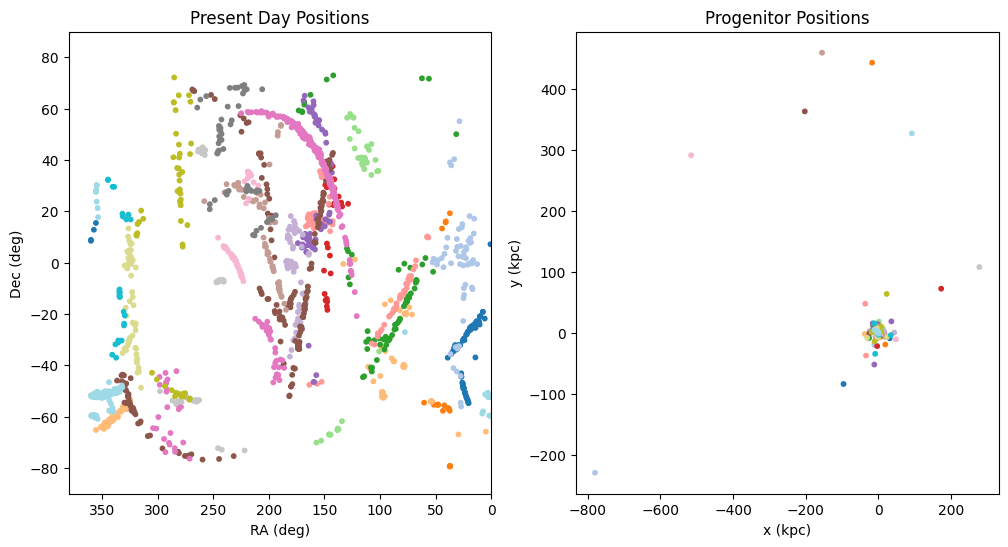

In [ ]:
# plotting part for verification
plt.figure(figsize=(12, 6)) 
plt.subplot(1, 2, 1)
plt.scatter(df_target['RA'], df_target['Dec'], s=10, c=df_target['Stream_ID'], cmap ='tab20')
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.xlim(0, 380)
plt.ylim(-90, 90)
plt.title('Present Day Positions')
plt.gca().invert_xaxis()        

plt.subplot(1, 2, 2)    
ra_prog = o_center.ra(ts[-1])
dec_prog = o_center.dec(ts[-1])

plt.scatter(seeds_array[:, 1], seeds_array[:, 2], c=seeds_array[:, 0], s=10, cmap ='tab20')
plt.xlabel('x (kpc)')
plt.ylabel('y (kpc)') 

plt.title('Progenitor Positions')
